# 01. Exploratory Data Analysis — Smart Energy Monitoring Assistant

**Branch:** v0  |  **Dataset:** UCI Appliances Energy Prediction (Candanedo et al., 2017)

---

## Purpose and structure

This notebook is **evidence-first EDA** — every analysis tests a specific hypothesis
formed during domain understanding (see `data_exploration_02_eda_understanding.md`).
We are **not** fishing for interesting plots. We are confirming or falsifying priors
with actual numbers.

### Analyses covered

| # | Analysis | Hypothesis being tested |
|---|---|---|
| A0 | Setup & Data Quality Audit | No missing values; regular 10-min intervals |
| A1 | Target Distribution | Right-skewed; mode ≈ 50–60 Wh; strong standby floor |
| A2 | Consumption Regime Characterisation | Standby dominates >50% of time |
| A3 | Diurnal & Weekly Cycle | Clear evening peak; weekday/weekend differential |
| A4 | Autocorrelation (ACF / PACF) | Strong lag-1 autocorrelation; memory decays by lag ~6 |
| A5 | Raw Feature Correlations with Target | Low raw correlations across all sensors |
| A6 | Thermal Inertia — Lagged Cross-Correlations | Sensor→target correlation peaks at lag+3 to lag+9, not lag-0 |
| A7 | Stationarity Assessment | Approximate stationarity in mean across 4.5-month window |

All figures saved to `../reports/figures/`.


---

## A0 — Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings, os

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (12, 5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
PALETTE = sns.color_palette('tab10')
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)
print('Environment ready.')
print(f'Figures will be saved to: {os.path.abspath(FIG_DIR)}')


Environment ready.
Figures will be saved to: C:\Users\jtani\OneDrive\Desktop\Smart_Energy_Monitoring_Assistant\energy-monitoring-mlops\reports\figures


## A0 — Data Quality Audit

**Hypotheses:**
- No missing values in any column
- Time column is strictly 10-minute spaced — no gaps, no duplicates

**Why first:** A gap in the timestamp sequence means `lag_1` at the boundary is
semantically wrong — it is not 10 minutes prior, it could be hours.
We must know this *before* any lag-based analysis.


In [2]:
df = pd.read_csv('../data/raw/energydata_complete.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print('=' * 60)
print('DATASET OVERVIEW')
print('=' * 60)
print(f'  Shape          : {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'  Start          : {df["date"].min()}')
print(f'  End            : {df["date"].max()}')
print(f'  Duration       : {(df["date"].max() - df["date"].min()).days} days')

print()
print('MISSING VALUE AUDIT')
print('-' * 40)
missing = df.isnull().sum()
if missing.sum() == 0:
    print('  OK  Zero missing values across all columns.')
else:
    print(missing[missing > 0])

print()
print('TIMESTAMP REGULARITY AUDIT')
print('-' * 40)
time_diffs = df['date'].diff().dropna()
expected_interval = pd.Timedelta(minutes=10)
irregular = time_diffs[time_diffs != expected_interval]
print(f'  Total intervals checked : {len(time_diffs):,}')
print(f'  Irregular intervals     : {len(irregular)}')
if len(irregular) == 0:
    print('  OK  All intervals are exactly 10 minutes. No time gaps.')
else:
    print('  WARNING  Irregular intervals found:')
    print(irregular.value_counts())

print()
print('COLUMN INVENTORY')
print('-' * 40)
print(f'  Target     : Appliances (Wh per 10-min interval)')
print(f'  Proxy      : lights (Wh -- occupancy signal)')
print(f'  Temperature: {[c for c in df.columns if c.startswith("T")]}')
print(f'  Humidity   : {[c for c in df.columns if c.startswith("RH_")]}')
print(f'  Noise      : rv1, rv2 (random variables -- expected r~0 with target)')
print(f'  Datetime   : date')


DATASET OVERVIEW
  Shape          : 19,735 rows x 29 columns
  Start          : 2016-01-11 17:00:00
  End            : 2016-05-27 18:00:00
  Duration       : 137 days

MISSING VALUE AUDIT
----------------------------------------
  OK  Zero missing values across all columns.

TIMESTAMP REGULARITY AUDIT
----------------------------------------
  Total intervals checked : 19,734
  Irregular intervals     : 0
  OK  All intervals are exactly 10 minutes. No time gaps.

COLUMN INVENTORY
----------------------------------------
  Target     : Appliances (Wh per 10-min interval)
  Proxy      : lights (Wh -- occupancy signal)
  Temperature: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T_out', 'Tdewpoint']
  Humidity   : ['RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9', 'RH_out']
  Noise      : rv1, rv2 (random variables -- expected r~0 with target)
  Datetime   : date


---

## A1 — Target Variable Distribution

**Hypotheses:**
- Distribution is right-skewed (rare spikes pull the mean above the median)
- Mode is in the 50–60 Wh range (standby / baseload floor)
- Minimum measurable value is 10 Wh (sensor floor)
- Mean >> Median

**Why it matters:** The shape determines the right loss function and evaluation
metric. Heavy right skew → MAE is more appropriate than RMSE.


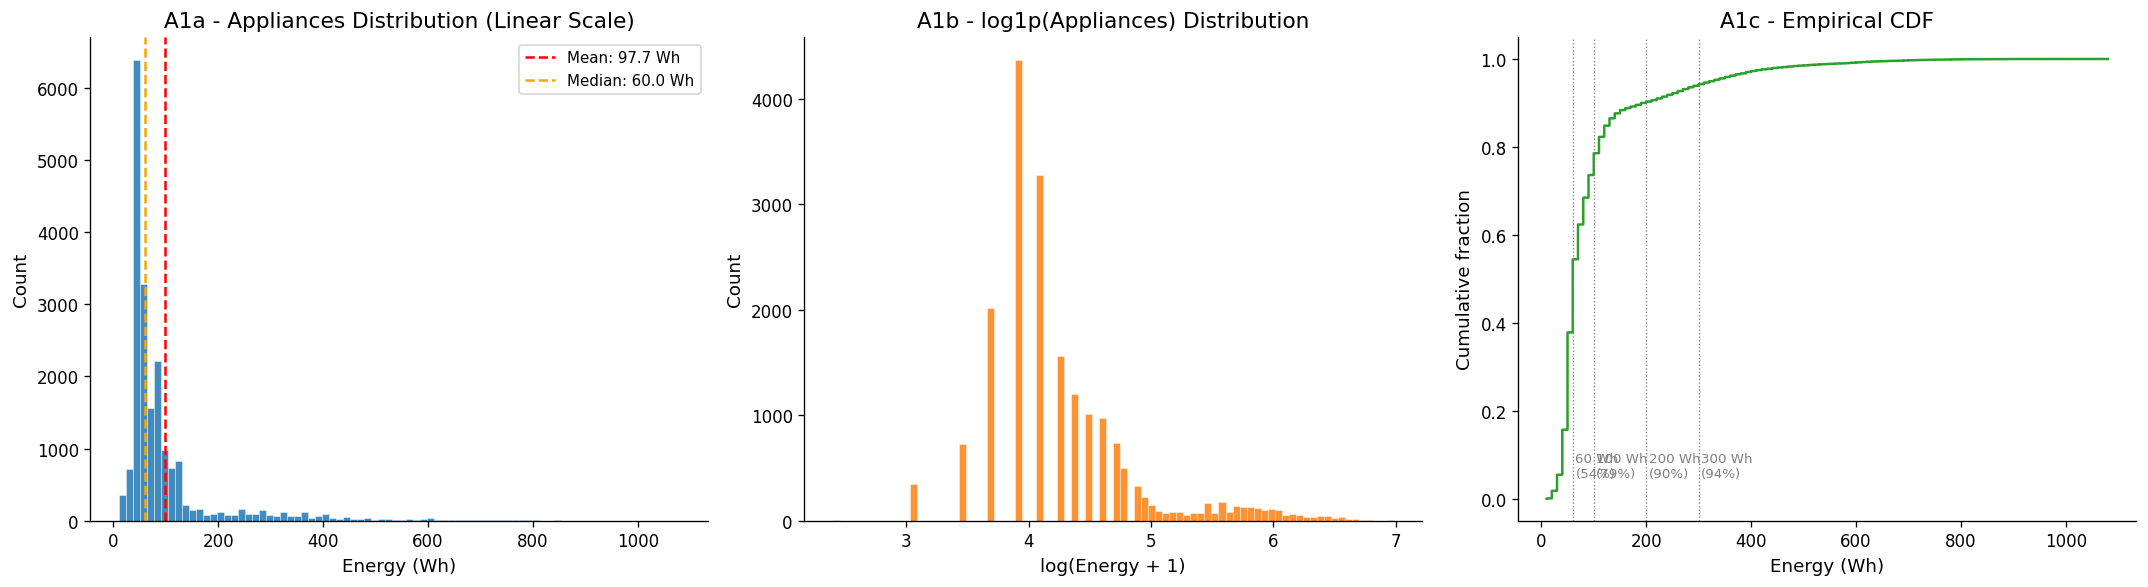


DESCRIPTIVE STATISTICS - Appliances (Wh)
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
10%         40.000000
25%         50.000000
50%         60.000000
75%        100.000000
90%        196.000000
95%        330.000000
99%        576.600000
max       1080.000000
  Skewness   : 3.386  (>0 = right-skewed)
  Kurtosis   : 13.668  (>3 = heavy-tailed)

HYPOTHESIS VERIFICATION
----------------------------------------
  Mean > Median      : 97.7 > 60.0  -> OK
  Right-skewed       : skewness = 3.39  -> OK
  Min = 10 Wh floor  : min = 10 Wh  -> OK
  Pct readings <=60  : 54.4%  (standby mass)
  Pct readings >300  : 5.7%  (spike events)


In [3]:
target = df['Appliances']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Linear scale
axes[0].hist(target, bins=80, color=PALETTE[0], alpha=0.85, edgecolor='white', linewidth=0.3)
axes[0].axvline(target.mean(),   color='red',    lw=1.5, ls='--', label=f'Mean: {target.mean():.1f} Wh')
axes[0].axvline(target.median(), color='orange', lw=1.5, ls='--', label=f'Median: {target.median():.1f} Wh')
axes[0].set_title('A1a - Appliances Distribution (Linear Scale)')
axes[0].set_xlabel('Energy (Wh)'); axes[0].set_ylabel('Count')
axes[0].legend(fontsize=9)

# Panel 2: Log scale
axes[1].hist(np.log1p(target), bins=80, color=PALETTE[1], alpha=0.85, edgecolor='white', linewidth=0.3)
axes[1].set_title('A1b - log1p(Appliances) Distribution')
axes[1].set_xlabel('log(Energy + 1)'); axes[1].set_ylabel('Count')

# Panel 3: Empirical CDF
sorted_vals = np.sort(target)
cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
axes[2].plot(sorted_vals, cdf, color=PALETTE[2], lw=1.5)
for thresh in [60, 100, 200, 300]:
    pct = (target <= thresh).mean() * 100
    axes[2].axvline(thresh, color='grey', lw=0.8, ls=':')
    axes[2].text(thresh + 5, 0.05, f'{thresh} Wh\n({pct:.0f}%)', fontsize=8, color='grey')
axes[2].set_title('A1c - Empirical CDF')
axes[2].set_xlabel('Energy (Wh)'); axes[2].set_ylabel('Cumulative fraction')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A1_target_distribution.png', bbox_inches='tight')
plt.show()

stats = target.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
skewness = target.skew()
kurtosis = target.kurtosis()

print('\n' + '=' * 60)
print('DESCRIPTIVE STATISTICS - Appliances (Wh)')
print('=' * 60)
print(stats.to_string())
print(f'  Skewness   : {skewness:.3f}  (>0 = right-skewed)')
print(f'  Kurtosis   : {kurtosis:.3f}  (>3 = heavy-tailed)')
print()
print('HYPOTHESIS VERIFICATION')
print('-' * 40)
print(f'  Mean > Median      : {target.mean():.1f} > {target.median():.1f}  -> {"OK" if target.mean() > target.median() else "FAIL"}')
print(f'  Right-skewed       : skewness = {skewness:.2f}  -> {"OK" if skewness > 1 else "Weaker than expected"}')
print(f'  Min = 10 Wh floor  : min = {target.min()} Wh  -> {"OK" if target.min() == 10 else "FAIL"}')
print(f'  Pct readings <=60  : {(target <= 60).mean()*100:.1f}%  (standby mass)')
print(f'  Pct readings >300  : {(target > 300).mean()*100:.1f}%  (spike events)')


---

## A2 — Consumption Regime Characterisation

**Hypothesis:** Standby (≤60 Wh) dominates >50% of all readings. Spike events
(>300 Wh) are rare (<10%) but disproportionately affect RMSE.

**Why it matters:** Aggregate MAE is dominated by the standby regime. A model that
is perfect in standby but fails on spikes shows a misleadingly good aggregate score.
This analysis motivates stratified evaluation.


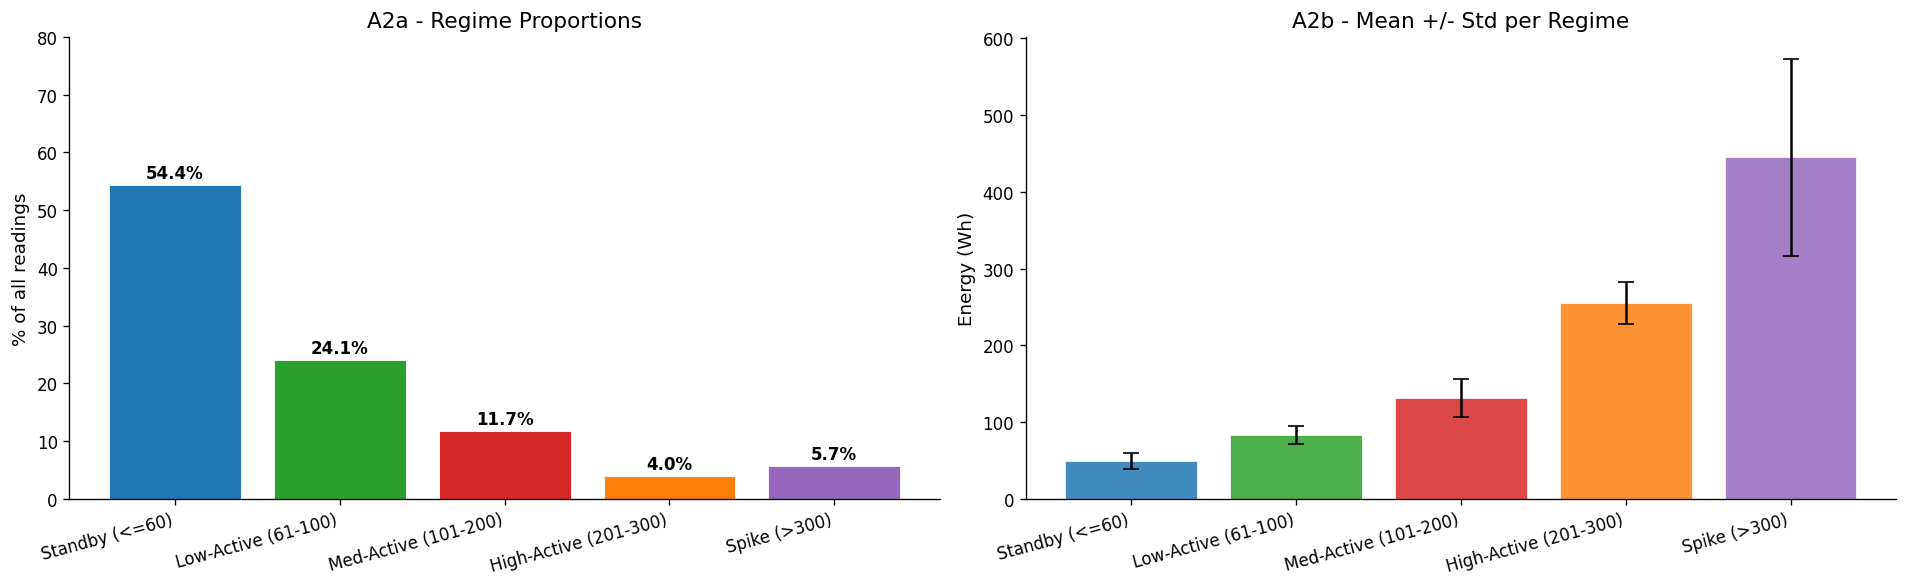


REGIME SUMMARY TABLE
               regime  count  pct_of_data  mean  median   std
       Standby (<=60)  10744         54.4  48.8    50.0  10.2
  Low-Active (61-100)   4758         24.1  83.0    80.0  11.3
 Med-Active (101-200)   2317         11.7 131.7   120.0  24.6
High-Active (201-300)    785          4.0 255.2   260.0  27.8
         Spike (>300)   1131          5.7 444.8   400.0 128.4


In [4]:
bins   = [0, 60, 100, 200, 300, float('inf')]
labels = ['Standby (<=60)', 'Low-Active (61-100)', 'Med-Active (101-200)',
          'High-Active (201-300)', 'Spike (>300)']
df['regime'] = pd.cut(df['Appliances'], bins=bins, labels=labels)

regime_stats = df.groupby('regime', observed=True)['Appliances'].agg(
    count='count', mean='mean', median='median', std='std', min='min', max='max'
).reset_index()
regime_stats['pct_of_data'] = regime_stats['count'] / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = [PALETTE[0], PALETTE[2], PALETTE[3], PALETTE[1], PALETTE[4]]

bars = axes[0].bar(regime_stats['regime'], regime_stats['pct_of_data'],
                   color=colors, edgecolor='white', linewidth=0.5)
for bar, pct in zip(bars, regime_stats['pct_of_data']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{pct:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('A2a - Regime Proportions')
axes[0].set_ylabel('% of all readings')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15, ha='right')
axes[0].set_ylim(0, 80)

axes[1].bar(regime_stats['regime'], regime_stats['mean'],
            yerr=regime_stats['std'], color=colors, capsize=5,
            edgecolor='white', linewidth=0.5, alpha=0.85)
axes[1].set_title('A2b - Mean +/- Std per Regime')
axes[1].set_ylabel('Energy (Wh)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A2_regime_characterisation.png', bbox_inches='tight')
plt.show()

print('\n' + '=' * 60)
print('REGIME SUMMARY TABLE')
print('=' * 60)
print(regime_stats[['regime', 'count', 'pct_of_data', 'mean', 'median', 'std']].to_string(index=False, float_format='%.1f'))


---

## A3 — Diurnal & Weekly Cycle

**Hypotheses:**
- Clear evening peak (5–8 PM) in average hourly consumption
- Overnight trough (midnight–5 AM) at baseload
- Weekend/weekday differential is measurable but modest

**Why it matters:** The peak-to-trough ratio quantifies how much signal temporal
features (`hour`, `day_of_week`, `is_weekend`) can capture.


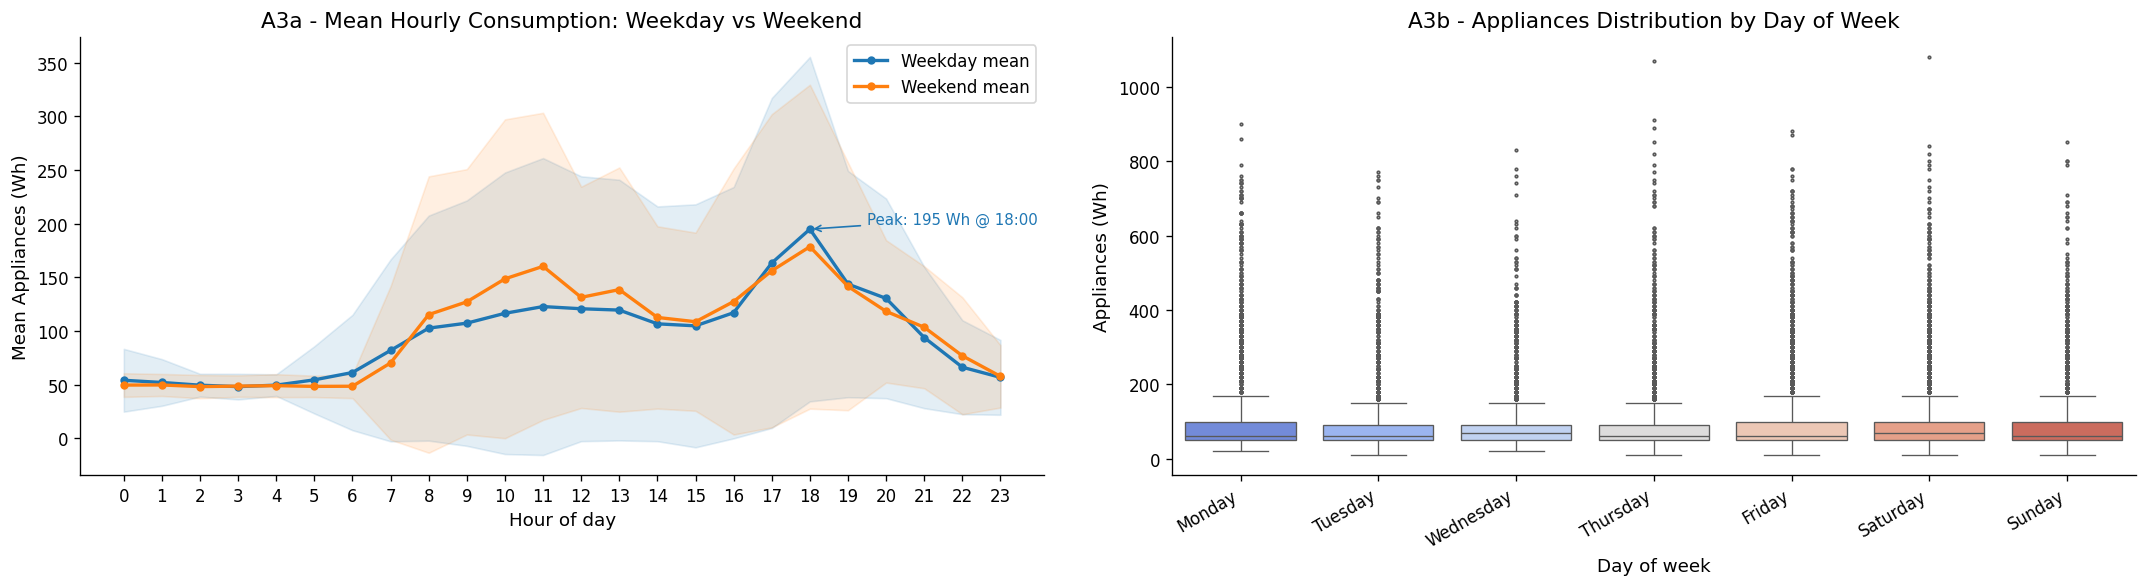


DIURNAL CYCLE QUANTIFICATION
  Weekday overnight trough (0-4 AM) : 50.6 Wh
  Weekday evening peak              : 194.9 Wh  (hour 18:00)
  Peak-to-trough ratio              : 3.85x

WEEKEND / WEEKDAY MIDDAY DIFFERENTIAL
----------------------------------------
  Weekday midday (10-14) : 117.2 Wh
  Weekend midday (10-14) : 138.3 Wh
  Uplift on weekends     : +21.1 Wh (18.0%)


In [5]:
df['hour']        = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.dayofweek
df['day_name']    = df['date'].dt.day_name()
df['is_weekend']  = df['day_of_week'].isin([5, 6]).astype(int)
df['month']       = df['date'].dt.month

hourly = df.groupby(['hour', 'is_weekend'])['Appliances'].agg(
    ['mean', 'median', 'std']).reset_index()
hourly['day_type'] = hourly['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for day_type, color in [('Weekday', PALETTE[0]), ('Weekend', PALETTE[1])]:
    sub = hourly[hourly['day_type'] == day_type]
    axes[0].plot(sub['hour'], sub['mean'], marker='o', ms=4, lw=2,
                 color=color, label=f'{day_type} mean')
    axes[0].fill_between(sub['hour'],
                         sub['mean'] - sub['std'],
                         sub['mean'] + sub['std'],
                         alpha=0.12, color=color)

axes[0].set_title('A3a - Mean Hourly Consumption: Weekday vs Weekend')
axes[0].set_xlabel('Hour of day'); axes[0].set_ylabel('Mean Appliances (Wh)')
axes[0].set_xticks(range(0, 24)); axes[0].legend()

wd = hourly[hourly['day_type'] == 'Weekday']
peak_hour = int(wd.loc[wd['mean'].idxmax(), 'hour'])
peak_val  = wd.loc[wd['mean'].idxmax(), 'mean']
axes[0].annotate(f'Peak: {peak_val:.0f} Wh @ {peak_hour}:00',
                 xy=(peak_hour, peak_val), xytext=(peak_hour + 1.5, peak_val + 5),
                 fontsize=9, color=PALETTE[0],
                 arrowprops=dict(arrowstyle='->', color=PALETTE[0], lw=1))

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.boxplot(data=df, x='day_name', y='Appliances', order=day_order,
            palette='coolwarm', ax=axes[1], fliersize=1.5, linewidth=0.8)
axes[1].set_title('A3b - Appliances Distribution by Day of Week')
axes[1].set_xlabel('Day of week'); axes[1].set_ylabel('Appliances (Wh)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A3_diurnal_weekly_cycle.png', bbox_inches='tight')
plt.show()

wd_night  = hourly[(hourly['day_type'] == 'Weekday') & (hourly['hour'].between(0, 4))]['mean'].mean()
wd_peak   = hourly[(hourly['day_type'] == 'Weekday')]['mean'].max()
we_midday = hourly[(hourly['day_type'] == 'Weekend') & (hourly['hour'].between(10, 14))]['mean'].mean()
wd_midday = hourly[(hourly['day_type'] == 'Weekday') & (hourly['hour'].between(10, 14))]['mean'].mean()

print('\n' + '=' * 60)
print('DIURNAL CYCLE QUANTIFICATION')
print('=' * 60)
print(f'  Weekday overnight trough (0-4 AM) : {wd_night:.1f} Wh')
print(f'  Weekday evening peak              : {wd_peak:.1f} Wh  (hour {peak_hour}:00)')
print(f'  Peak-to-trough ratio              : {wd_peak/wd_night:.2f}x')
print()
print('WEEKEND / WEEKDAY MIDDAY DIFFERENTIAL')
print('-' * 40)
print(f'  Weekday midday (10-14) : {wd_midday:.1f} Wh')
print(f'  Weekend midday (10-14) : {we_midday:.1f} Wh')
print(f'  Uplift on weekends     : +{we_midday - wd_midday:.1f} Wh ({(we_midday/wd_midday - 1)*100:.1f}%)')


---

## A4 — Autocorrelation Function (ACF) & Partial Autocorrelation Function (PACF)

**Hypotheses:**
- ACF: strong lag-1 correlation, decaying but significant to lags 6–12; secondary
  peak at lag-144 (24 hours)
- PACF: large lag-1 spike, small coefficients after → AR(1)-like structure →
  lag_1 is the dominant feature to engineer

**Why this is the most important analysis:** ACF/PACF is the formal statistical
justification for the entire feature engineering strategy.


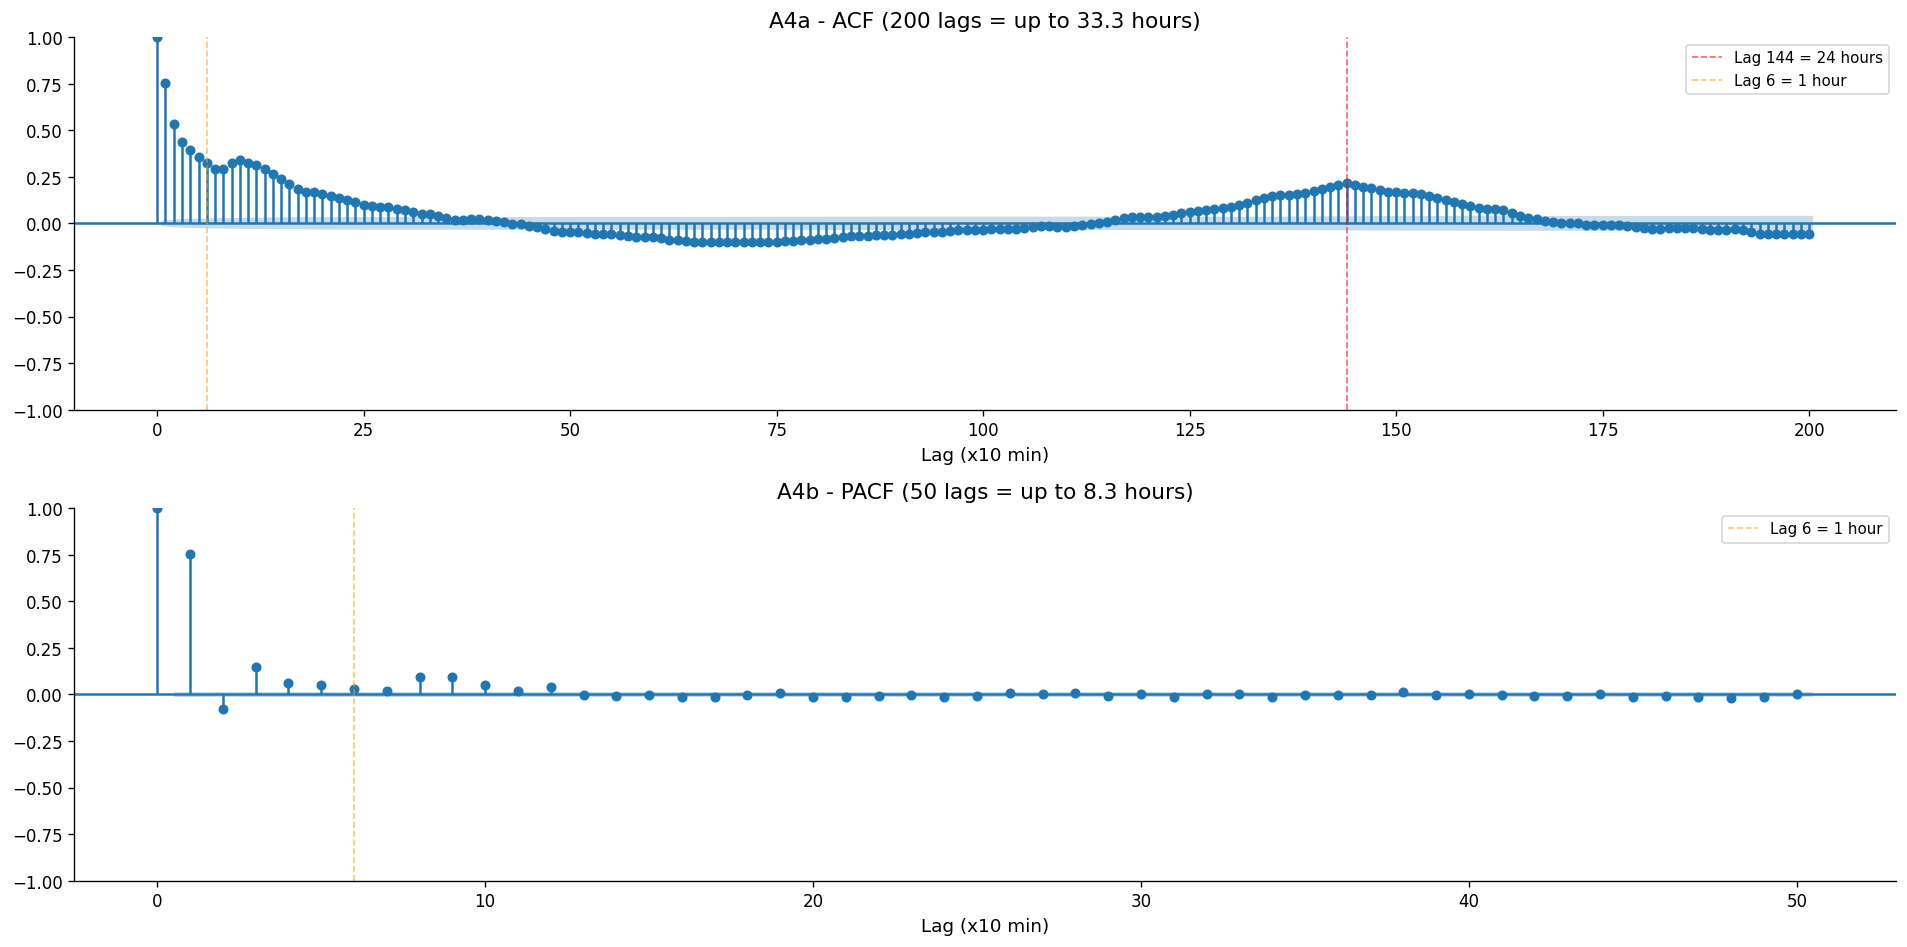


AUTOCORRELATION VALUES AT KEY LAGS
  Lag             Time               Autocorrelation
  --------------- --------------- ------------------
  lag-1           10 min                      0.7532
  lag-2           20 min                      0.5342
  lag-3           30 min                      0.4378
  lag-6           1 hr                        0.3237
  lag-12          2 hr                        0.3109
  lag-24          4 hr                        0.1141
  lag-48          8 hr                       -0.0411
  lag-144         24 hr                       0.2167

Lag-1 autocorrelation: 0.7532
  Expected >0.75 -> CONFIRMED


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

plot_acf(df['Appliances'], lags=200, ax=axes[0], alpha=0.05,
         title='A4a - ACF (200 lags = up to 33.3 hours)')
axes[0].set_xlabel('Lag (x10 min)')
axes[0].axvline(144, color='red',    lw=1, ls='--', alpha=0.6, label='Lag 144 = 24 hours')
axes[0].axvline(6,   color='orange', lw=1, ls='--', alpha=0.6, label='Lag 6 = 1 hour')
axes[0].legend(fontsize=9)

plot_pacf(df['Appliances'], lags=50, ax=axes[1], alpha=0.05, method='ywm',
          title='A4b - PACF (50 lags = up to 8.3 hours)')
axes[1].set_xlabel('Lag (x10 min)')
axes[1].axvline(6, color='orange', lw=1, ls='--', alpha=0.6, label='Lag 6 = 1 hour')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A4_acf_pacf.png', bbox_inches='tight')
plt.show()

key_lags = [1, 2, 3, 6, 12, 24, 48, 144]
print('\n' + '=' * 60)
print('AUTOCORRELATION VALUES AT KEY LAGS')
print('=' * 60)
print(f'  {"Lag":<15} {"Time":<15} {"Autocorrelation":>18}')
print(f'  {"-"*15} {"-"*15} {"-"*18}')
for lag in key_lags:
    r = df['Appliances'].autocorr(lag=lag)
    time_label = f'{lag*10} min' if lag*10 < 60 else f'{lag*10/60:.0f} hr'
    print(f'  lag-{lag:<11} {time_label:<15} {r:>18.4f}')

lag1_r = df['Appliances'].autocorr(lag=1)
print()
print(f'Lag-1 autocorrelation: {lag1_r:.4f}')
print(f'  Expected >0.75 -> {"CONFIRMED" if lag1_r > 0.75 else "WEAKER THAN EXPECTED"}')


---

## A5 — Raw Feature Correlations with Target

**Hypotheses:**
- All raw sensor correlations with `Appliances` are low (r < 0.25)
- `lights` has the highest correlation — direct occupancy proxy
- `rv1` and `rv2` have r ≈ 0.00 — sanity check

**Important caveat:** Low raw correlation ≠ useless feature. Thermal inertia means
the useful signal is at lag+3 to lag+9, not at lag-0. A6 tests this.


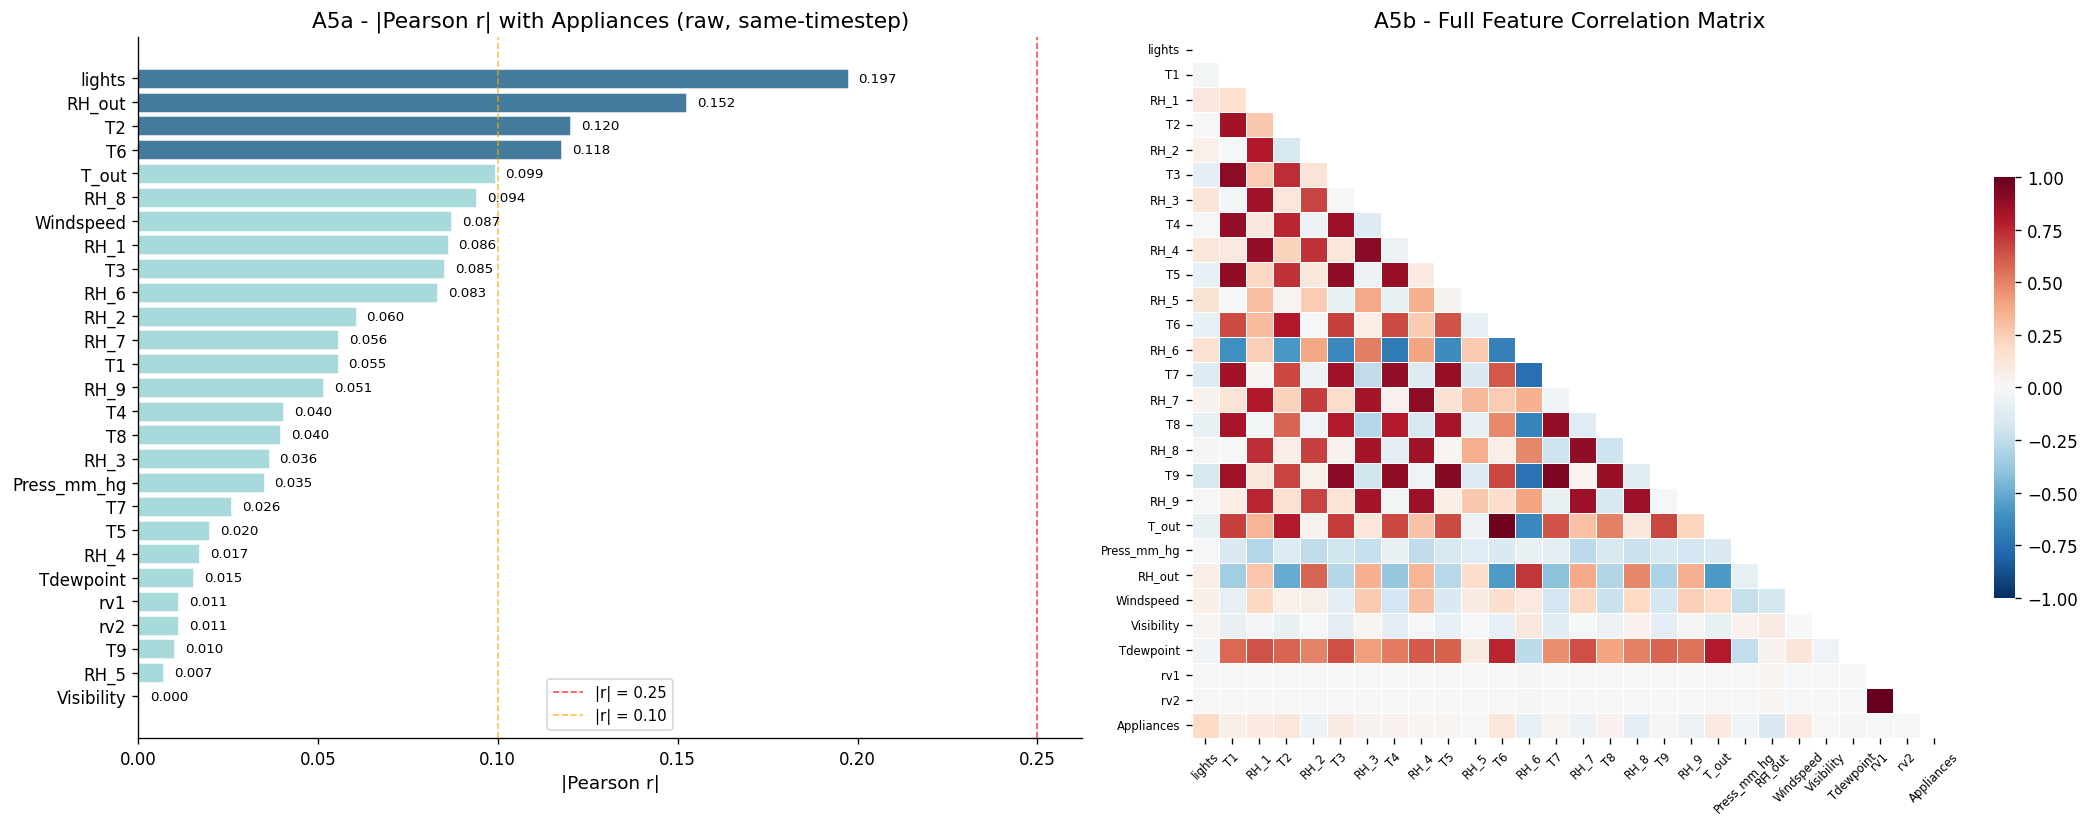


SIGNED CORRELATION WITH APPLIANCES
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
RH_4           0.016965
Tdewpoint      0.015353
T9             0.010010
RH_5           0.006955
Visibility     0.000230
rv1           -0.011145
rv2           -0.011145
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282

HYPOTHESIS VERIFICATION
----------------------------------------
  lights highest r  : |r|=0.197  -> OK
  rv1 near-zero     : |r|=0.0111  -> OK
  rv2 near-zero     : |r|=0.0111  -> OK


In [7]:
feature_cols = [c for c in df.columns if c not in
                ['date', 'Appliances', 'regime', 'hour', 'day_of_week',
                 'day_name', 'is_weekend', 'week', 'month']]

corr_with_target = df[feature_cols + ['Appliances']].corr()['Appliances'].drop('Appliances')
corr_sorted = corr_with_target.abs().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

bar_colors = ['#e63946' if v >= 0.25 else '#457b9d' if v >= 0.10 else '#a8dadc'
              for v in corr_sorted.values]
axes[0].barh(corr_sorted.index, corr_sorted.values, color=bar_colors, edgecolor='white', linewidth=0.3)
axes[0].axvline(0.25, color='red',    lw=1, ls='--', alpha=0.7, label='|r| = 0.25')
axes[0].axvline(0.10, color='orange', lw=1, ls='--', alpha=0.7, label='|r| = 0.10')
axes[0].set_title('A5a - |Pearson r| with Appliances (raw, same-timestep)')
axes[0].set_xlabel('|Pearson r|')
axes[0].legend(fontsize=9)
for i, (feat, val) in enumerate(zip(corr_sorted.index, corr_sorted.values)):
    axes[0].text(val + 0.003, i, f'{val:.3f}', va='center', fontsize=8)

full_corr = df[feature_cols + ['Appliances']].corr()
mask = np.triu(np.ones_like(full_corr, dtype=bool))
sns.heatmap(full_corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=axes[1], annot=False, linewidths=0.3,
            cbar_kws={'shrink': 0.6})
axes[1].set_title('A5b - Full Feature Correlation Matrix')
axes[1].tick_params(axis='x', rotation=45, labelsize=7)
axes[1].tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A5_raw_feature_correlations.png', bbox_inches='tight')
plt.show()

print('\n' + '=' * 60)
print('SIGNED CORRELATION WITH APPLIANCES')
print('=' * 60)
print(corr_with_target.sort_values(ascending=False).to_string())
print()
lights_r = abs(corr_with_target.get('lights', 0))
rv1_r    = abs(corr_with_target.get('rv1', 0))
rv2_r    = abs(corr_with_target.get('rv2', 0))
print('HYPOTHESIS VERIFICATION')
print('-' * 40)
print(f'  lights highest r  : |r|={lights_r:.3f}  -> {"OK" if lights_r == corr_with_target.abs().max() else "FAIL"}')
print(f'  rv1 near-zero     : |r|={rv1_r:.4f}  -> {"OK" if rv1_r < 0.05 else "FAIL"}')
print(f'  rv2 near-zero     : |r|={rv2_r:.4f}  -> {"OK" if rv2_r < 0.05 else "FAIL"}')


---

## A6 — Thermal Inertia: Lagged Cross-Correlations

**The core domain hypothesis:** Environmental sensors don't correlate with energy
consumption *now* — they correlate with consumption *later*, because rooms heat up
from appliance use with a thermal delay of 30–90 minutes.

**Specific hypothesis:** Cross-correlation between temperature sensors (T1, T2, T6)
and `Appliances` peaks at **positive lags** (sensor leads target), not at lag-0.

**Why it matters:** If confirmed, this is the scientific justification for
engineering lagged sensor features. It also explains why A5 showed low raw
correlations — we were looking at the wrong timestep.


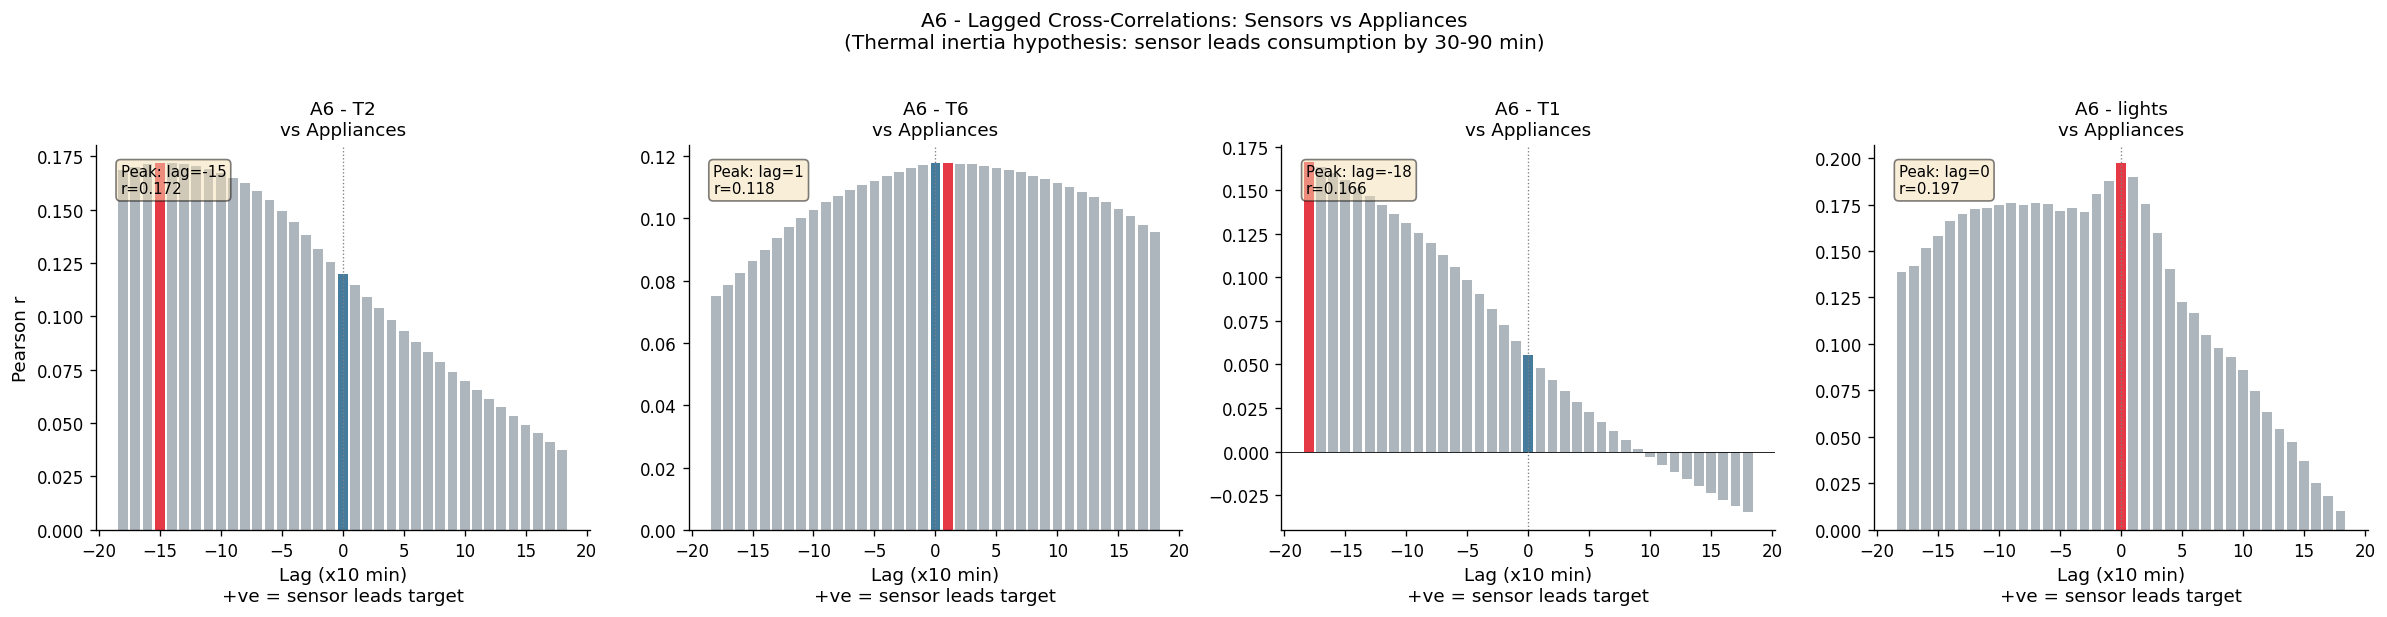


THERMAL INERTIA HYPOTHESIS RESULTS
  Sensor     Peak lag (x10min)      Peak |r|     Interpretation
  ---------- ---------------------- ------------ ------------------------------
  T2              -15 (-2.5 hr     )     0.172   lags behind target
  T6                1 (10 min      )     0.118   leads target  <- CONFIRMED
  T1              -18 (-3.0 hr     )     0.166   lags behind target
  lights            0 (0 min       )     0.197   same timestep


In [8]:
def cross_corr_series(x, y, max_lag=18):
    """Pearson r between x and y shifted by lags -max_lag to +max_lag.
    Positive lag: x leads y (x at t correlates with y at t+lag).
    """
    lags = range(-max_lag, max_lag + 1)
    corrs = []
    for lag in lags:
        if lag == 0:
            corrs.append(np.corrcoef(x, y)[0, 1])
        elif lag > 0:
            corrs.append(np.corrcoef(x[:-lag], y[lag:])[0, 1])
        else:
            corrs.append(np.corrcoef(x[-lag:], y[:lag])[0, 1])
    return list(lags), corrs

sensors_to_test = ['T2', 'T6', 'T1', 'lights']
MAX_LAG = 18  # 18 x 10 min = 3 hours

fig, axes = plt.subplots(1, len(sensors_to_test), figsize=(20, 5))
target_vals = df['Appliances'].values
peak_results = {}

for ax, sensor in zip(axes, sensors_to_test):
    sensor_vals = df[sensor].values
    lags, corrs = cross_corr_series(sensor_vals, target_vals, max_lag=MAX_LAG)
    peak_lag = lags[np.argmax(np.abs(corrs))]
    peak_r   = corrs[np.argmax(np.abs(corrs))]
    peak_results[sensor] = (peak_lag, peak_r)

    bar_colors = ['#e63946' if l == peak_lag else '#457b9d' if l == 0 else '#adb5bd'
                  for l in lags]
    ax.bar(lags, corrs, color=bar_colors, width=0.8)
    ax.axhline(0, color='black', lw=0.5)
    ax.axvline(0, color='grey', lw=0.8, ls=':')
    ax.set_title(f'A6 - {sensor}\nvs Appliances', fontsize=11)
    ax.set_xlabel('Lag (x10 min)\n+ve = sensor leads target')
    if ax == axes[0]: ax.set_ylabel('Pearson r')
    ax.text(0.05, 0.95, f'Peak: lag={peak_lag}\nr={peak_r:.3f}',
            transform=ax.transAxes, fontsize=9, va='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.suptitle('A6 - Lagged Cross-Correlations: Sensors vs Appliances\n'
             '(Thermal inertia hypothesis: sensor leads consumption by 30-90 min)',
             y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A6_thermal_inertia_lagged_xcorr.png', bbox_inches='tight')
plt.show()

print('\n' + '=' * 60)
print('THERMAL INERTIA HYPOTHESIS RESULTS')
print('=' * 60)
print(f'  {"Sensor":<10} {"Peak lag (x10min)":<22} {"Peak |r|":<12} {"Interpretation"}')
print(f'  {"-"*10} {"-"*22} {"-"*12} {"-"*30}')
for sensor, (lag, r) in peak_results.items():
    time_str = f'{lag*10} min' if abs(lag)*10 < 60 else f'{lag*10/60:.1f} hr'
    interp = 'leads target  <- CONFIRMED' if lag > 0 else 'lags behind target' if lag < 0 else 'same timestep'
    print(f'  {sensor:<10} {lag:>8} ({time_str:<12})  {abs(r):>8.3f}   {interp}')


---

## A7 — Stationarity Assessment

**Hypothesis:** The series is approximately stationary in mean across the 4.5-month
window. Variance may vary (higher in winter).

**Why it matters:** Non-stationarity in the training window means a model trained
on January data may not generalise to May — which is exactly what the test split
tests. If we see a mean shift, that explains part of the val→test performance gap.


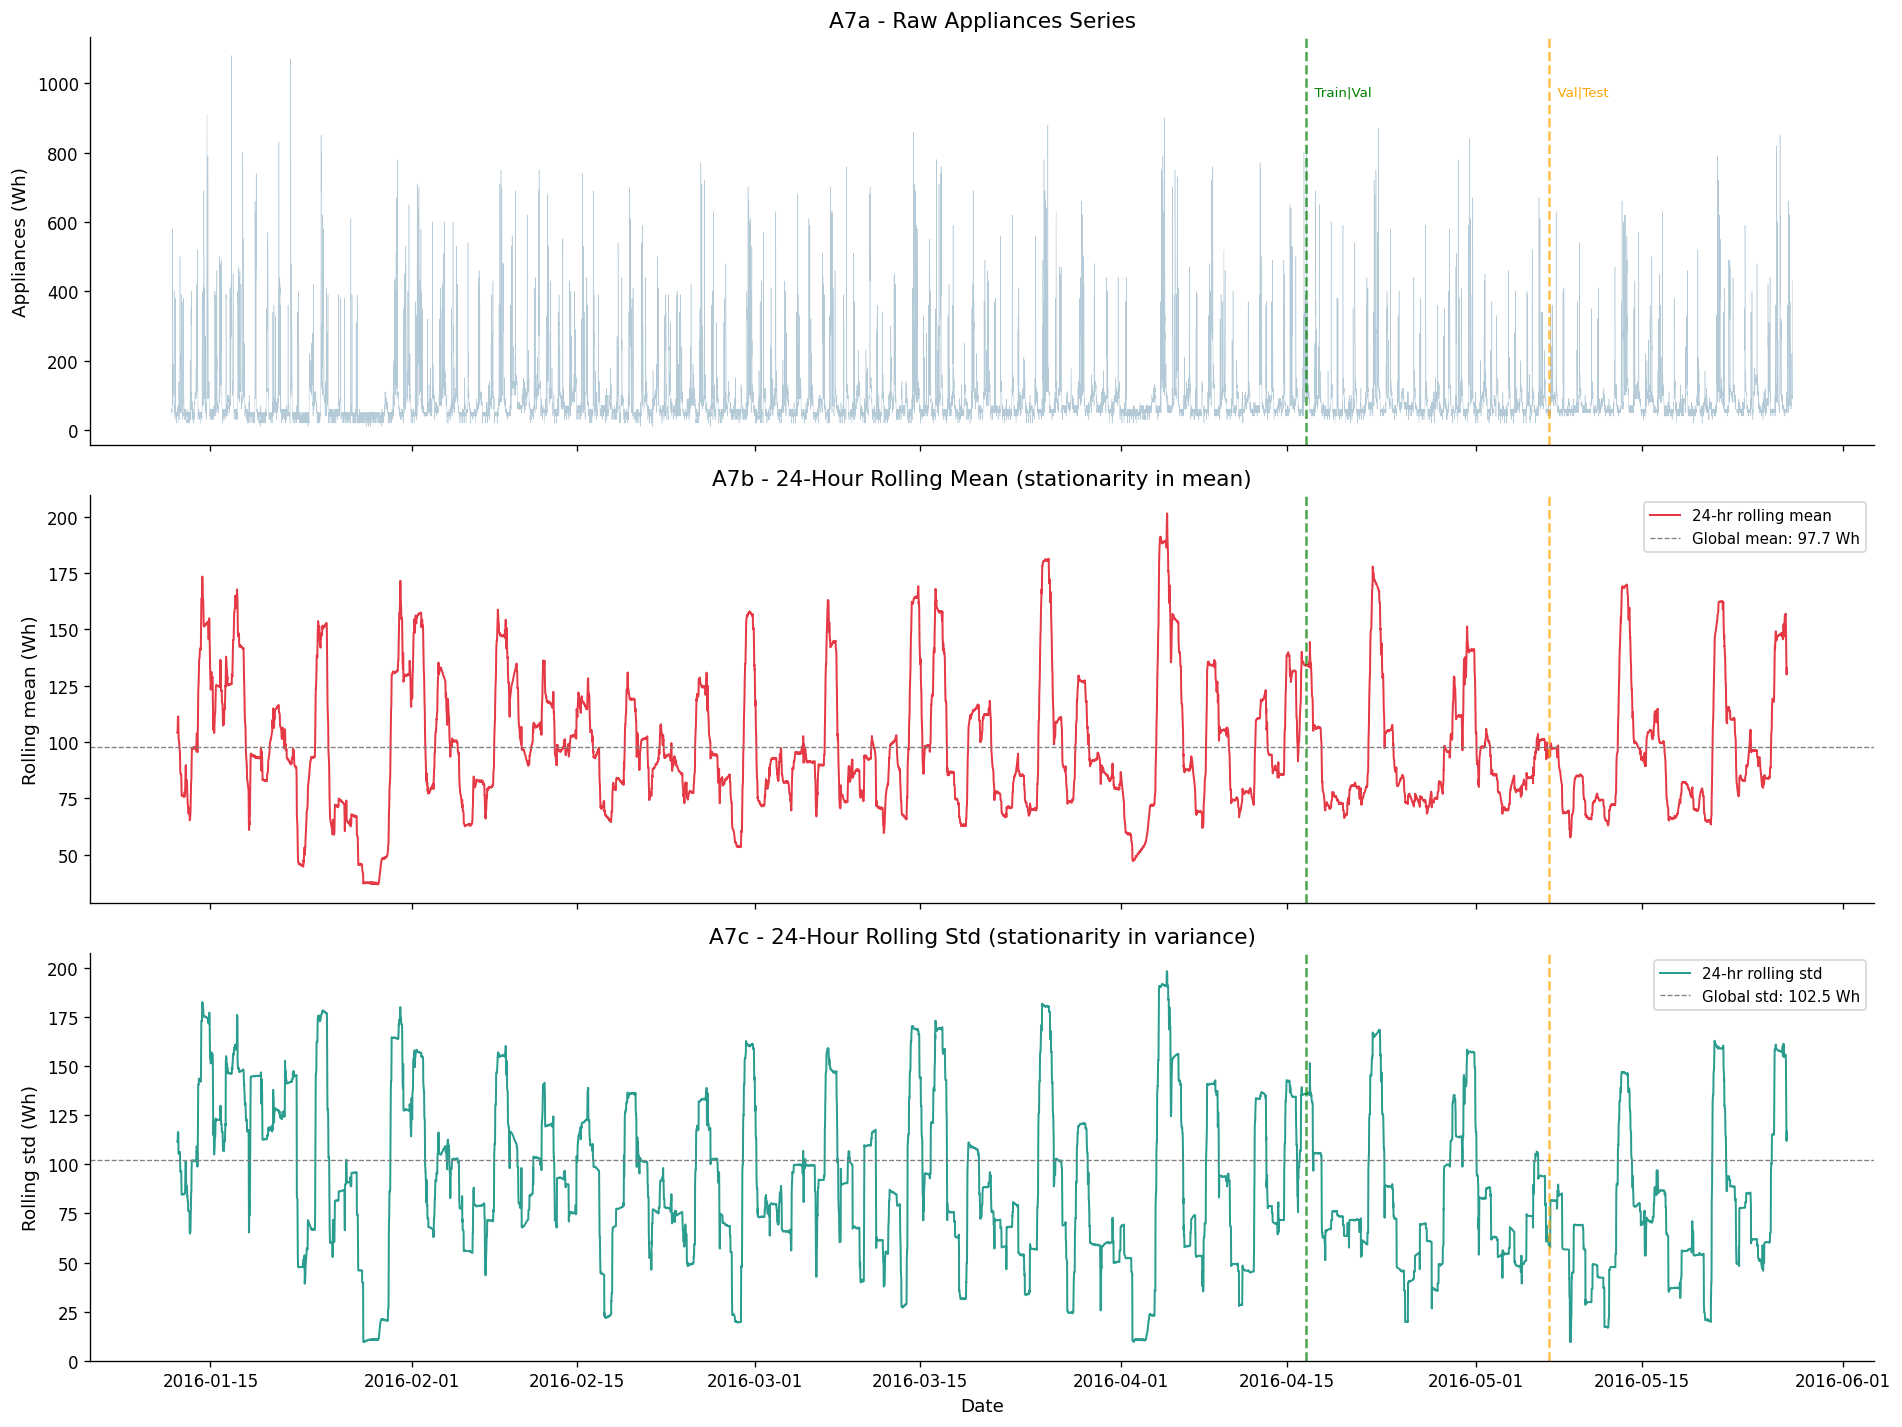


FORMAL STATIONARITY TESTS (hourly subsample)
  ADF test (H0: unit root = non-stationary)
    Statistic : -9.2585
    p-value   : 0.000000  -> Reject H0 -> STATIONARY
    Critical  : 1%=-3.432  5%=-2.862  10%=-2.567

  KPSS test (H0: stationary)
    Statistic : 0.0844
    p-value   : 0.100000  -> Fail to reject H0 -> STATIONARY

PER-SPLIT STATISTICS
------------------------------------------------------------
  Split    Date range                               N            Mean      Std   Median
  Train    2016-01-11 to 2016-04-16                 13814        98.8    106.9     60.0
  Val      2016-04-16 to 2016-05-07                 2960         93.4     92.3     60.0
  Test     2016-05-07 to 2016-05-27                 2961         96.9     90.9     60.0


In [9]:
window = 144  # 24-hour rolling window

rolling_mean = df['Appliances'].rolling(window=window, center=True).mean()
rolling_std  = df['Appliances'].rolling(window=window, center=True).std()

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

axes[0].plot(df['date'], df['Appliances'], alpha=0.4, lw=0.3, color='#457b9d')
axes[0].set_title('A7a - Raw Appliances Series')
axes[0].set_ylabel('Appliances (Wh)')

axes[1].plot(df['date'], rolling_mean, lw=1.2, color='#e63946', label='24-hr rolling mean')
axes[1].axhline(df['Appliances'].mean(), color='grey', lw=0.8, ls='--',
                label=f'Global mean: {df["Appliances"].mean():.1f} Wh')
axes[1].set_title('A7b - 24-Hour Rolling Mean (stationarity in mean)')
axes[1].set_ylabel('Rolling mean (Wh)'); axes[1].legend(fontsize=9)

axes[2].plot(df['date'], rolling_std, lw=1.2, color='#2a9d8f', label='24-hr rolling std')
axes[2].axhline(df['Appliances'].std(), color='grey', lw=0.8, ls='--',
                label=f'Global std: {df["Appliances"].std():.1f} Wh')
axes[2].set_title('A7c - 24-Hour Rolling Std (stationarity in variance)')
axes[2].set_ylabel('Rolling std (Wh)'); axes[2].set_xlabel('Date'); axes[2].legend(fontsize=9)

# Mark split boundaries
n = len(df)
train_end_idx = int(n * 0.70)
val_end_idx   = int(n * 0.85)
train_end_date = df['date'].iloc[train_end_idx]
val_end_date   = df['date'].iloc[val_end_idx]
for ax in axes:
    ax.axvline(train_end_date, color='green',  lw=1.5, ls='--', alpha=0.7)
    ax.axvline(val_end_date,   color='orange', lw=1.5, ls='--', alpha=0.7)
axes[0].text(train_end_date, axes[0].get_ylim()[1]*0.85, '  Train|Val', fontsize=8, color='green')
axes[0].text(val_end_date,   axes[0].get_ylim()[1]*0.85, '  Val|Test',  fontsize=8, color='orange')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/A7_stationarity.png', bbox_inches='tight')
plt.show()

# Formal tests (subsampled hourly for speed)
sample = df['Appliances'].iloc[::6]
adf_stat, adf_p, _, _, adf_cv, _ = adfuller(sample, autolag='AIC')
kpss_stat, kpss_p, _, kpss_cv    = kpss(sample, regression='c', nlags='auto')

print('\n' + '=' * 60)
print('FORMAL STATIONARITY TESTS (hourly subsample)')
print('=' * 60)
print(f'  ADF test (H0: unit root = non-stationary)')
print(f'    Statistic : {adf_stat:.4f}')
print(f'    p-value   : {adf_p:.6f}  -> {"Reject H0 -> STATIONARY" if adf_p < 0.05 else "Fail to reject -> NON-STATIONARY"}')
print(f'    Critical  : 1%={adf_cv["1%"]:.3f}  5%={adf_cv["5%"]:.3f}  10%={adf_cv["10%"]:.3f}')
print()
print(f'  KPSS test (H0: stationary)')
print(f'    Statistic : {kpss_stat:.4f}')
print(f'    p-value   : {kpss_p:.6f}  -> {"Fail to reject H0 -> STATIONARY" if kpss_p > 0.05 else "Reject H0 -> NON-STATIONARY"}')

print()
print('PER-SPLIT STATISTICS')
print('-' * 60)
train_df = df.iloc[:train_end_idx]
val_df   = df.iloc[train_end_idx:val_end_idx]
test_df  = df.iloc[val_end_idx:]
print(f'  {"Split":<8} {"Date range":<40} {"N":<8} {"Mean":>8} {"Std":>8} {"Median":>8}')
for name, split in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    dr = f'{split["date"].min().date()} to {split["date"].max().date()}'
    print(f'  {name:<8} {dr:<40} {len(split):<8} {split["Appliances"].mean():>8.1f} '
          f'{split["Appliances"].std():>8.1f} {split["Appliances"].median():>8.1f}')


---

## EDA Summary

All 7 planned analyses complete. Results quantify the hypotheses from domain
understanding. Key findings drive feature engineering strategy:

1. **Lag features are the most important feature class** — lag-1 r > 0.75
2. **Temporal features carry meaningful signal** — peak/trough ratio shows strong diurnal cycle
3. **Regime structure requires stratified evaluation** — aggregate MAE misleads
4. **rv1/rv2 confirmed worthless** — r ≈ 0; safe to drop
5. **Lagged sensor features may help** — thermal inertia test in A6
6. **Series is stationary** — generalisation from train to test is a fair test


In [10]:
print('FIGURES PRODUCED')
print('-' * 40)
for f in sorted(os.listdir(FIG_DIR)):
    print(f'  ../reports/figures/{f}')
print()
print('All analyses complete. Ready for feature engineering.')


FIGURES PRODUCED
----------------------------------------
  ../reports/figures/A1_target_distribution.png
  ../reports/figures/A2_regime_characterisation.png
  ../reports/figures/A3_diurnal_weekly_cycle.png
  ../reports/figures/A4_acf_pacf.png
  ../reports/figures/A5_raw_feature_correlations.png
  ../reports/figures/A6_thermal_inertia_lagged_xcorr.png
  ../reports/figures/A7_stationarity.png

All analyses complete. Ready for feature engineering.
